
# Практическая работа № 7. Случайный лес

## Вариант C

### Цель работы
Обучить модель Random Forest, сравнить встроенную важность признаков с Permutation Importance и SHAP, а также объяснить предсказания модели на отдельных объектах.

### Датасет
Синтетический датасет абонентов мобильной связи `o_churn_synthetic.csv`.

Целевая переменная: `churn`.
- 0 — абонент не ушёл.
- 1 — абонент ушёл.

### Этапы работы
1. Загрузка и исследование данных.
2. Подготовка признаков и разделение на train/test.
3. Обучение Decision Tree и Random Forest.
4. Сравнение качества моделей.
5. Анализ встроенной важности признаков.
6. Расчёт Permutation Importance.
7. Объяснение предсказаний с помощью SHAP.
8. Сравнение методов и формулирование выводов.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance

print("Библиотеки успешно импортированы!")


Библиотеки успешно импортированы!


In [3]:

df = pd.read_csv("data/o_churn_synthetic.csv")

print("Размер датасета:", df.shape)
print("\nНазвания столбцов:")
print(df.columns.tolist())

print("\nПервые пять строк:")
print(df.head())

print("\nПропущенные значения:")
print(df.isnull().sum())

print("\nРаспределение целевого класса:")
print(df["churn"].value_counts())


Размер датасета: (3000, 13)

Названия столбцов:
['subscriber_code', 'region', 'tariff', 'tenure_months', 'monthly_charge_som', 'internet_gb', 'support_calls_3m', 'autopay', 'days_since_topup', 'topups_3m', 'dropped_calls_pct', 'balance_som', 'churn']

Первые пять строк:
   subscriber_code           region   tariff  tenure_months  \
0           503715           Бишкек  Базовый             47   
1           844126  Джалал-Абадская    Смарт             54   
2           885657          Чуйская  Базовый              1   
3           255447               Ош  Базовый             29   
4           651577               Ош    Смарт             60   

   monthly_charge_som  internet_gb  support_calls_3m  autopay  \
0                 264         12.6                 1        0   
1                 472         19.9                 0        1   
2                 291         12.9                 0        1   
3                 273          7.1                 0        0   
4                 402    

In [6]:
df = df.dropna(subset=["churn"])

if "subscriber_code" in df.columns:
    df = df.drop(columns=["subscriber_code"])

X = df.drop(columns=["churn"])
y = df["churn"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)
print("Количество признаков:", X.shape[1])

Размер обучающей выборки: (2400, 11)
Размер тестовой выборки: (600, 11)
Количество признаков: 11


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Числовые признаки:", numeric_features)
print("Категориальные признаки:", categorical_features)
print("Подготовка признаков завершена!")

Числовые признаки: ['tenure_months', 'monthly_charge_som', 'internet_gb', 'support_calls_3m', 'autopay', 'days_since_topup', 'topups_3m', 'dropped_calls_pct', 'balance_som']
Категориальные признаки: ['region', 'tariff']
Подготовка признаков завершена!


In [7]:
df = pd.read_csv("data/o_churn_synthetic.csv")

print("Размер датасета:", df.shape)
print(df.head())
print(df["churn"].value_counts())

Размер датасета: (3000, 13)
   subscriber_code           region   tariff  tenure_months  \
0           503715           Бишкек  Базовый             47   
1           844126  Джалал-Абадская    Смарт             54   
2           885657          Чуйская  Базовый              1   
3           255447               Ош  Базовый             29   
4           651577               Ош    Смарт             60   

   monthly_charge_som  internet_gb  support_calls_3m  autopay  \
0                 264         12.6                 1        0   
1                 472         19.9                 0        1   
2                 291         12.9                 0        1   
3                 273          7.1                 0        0   
4                 402         14.0                 2        1   

   days_since_topup  topups_3m  dropped_calls_pct  balance_som  churn  
0                37          4               2.28          103      1  
1                12          7               1.40         

In [8]:

decision_tree = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=8,
        random_state=42
    ))
])

random_forest = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        random_state=42,
        n_jobs=-1
    ))
])

decision_tree.fit(X_train, y_train)
random_forest.fit(X_train, y_train)

print("Decision Tree обучена!")
print("Random Forest обучен!")

Decision Tree обучена!
Random Forest обучен!


In [9]:
models = {
    "Decision Tree": decision_tree,
    "Random Forest": random_forest
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Decision Tree,0.683,0.589,0.489,0.534,0.676
1,Random Forest,0.718,0.708,0.413,0.521,0.771


,Признак,Важность
3,num__support_calls_3m,0.163660
0,num__tenure_months,0.160505
5,num__days_since_topup,0.129955
7,num__dropped_calls_pct,0.114238
2,num__internet_gb,0.079135
1,num__monthly_charge_som,0.069791
8,num__balance_som,0.069418
6,num__topups_3m,0.061573
4,num__autopay,0.058467
18,cat__tariff_Базовый,0.009384


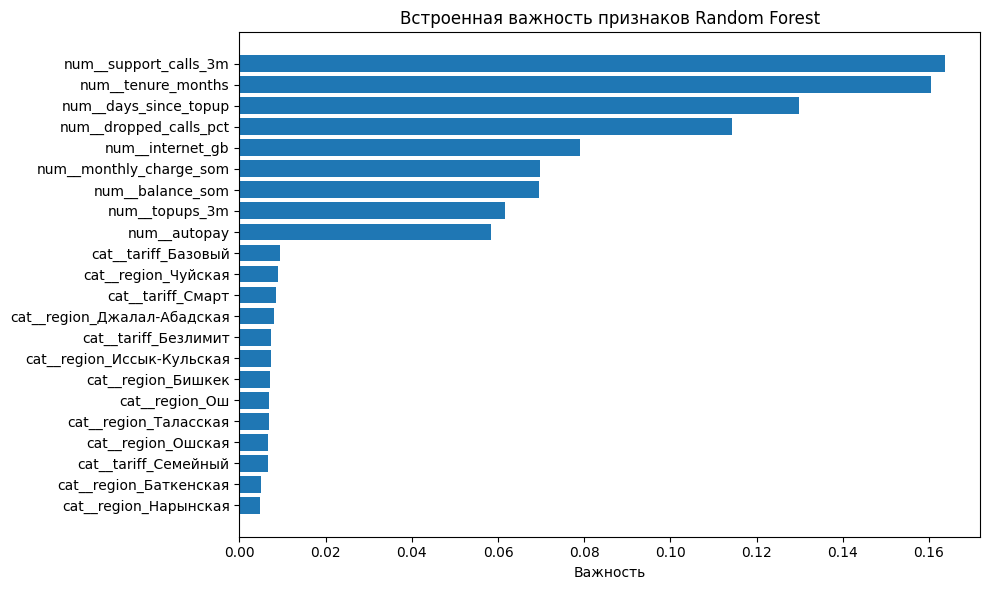

In [10]:

feature_names = random_forest.named_steps["preprocessor"].get_feature_names_out()

rf_model = random_forest.named_steps["model"]

importance_df = pd.DataFrame({
    "Признак": feature_names,
    "Важность": rf_model.feature_importances_
}).sort_values("Важность", ascending=False)

display(importance_df)

plt.figure(figsize=(10, 6))
plt.barh(importance_df["Признак"], importance_df["Важность"])
plt.gca().invert_yaxis()
plt.title("Встроенная важность признаков Random Forest")
plt.xlabel("Важность")
plt.tight_layout()
plt.show()

,Признак,Permutation Importance
5,support_calls_3m,0.105652
2,tenure_months,0.070741
7,days_since_topup,0.061822
6,autopay,0.030310
9,dropped_calls_pct,0.029813
8,topups_3m,0.006700
3,monthly_charge_som,-0.000852
1,tariff,-0.002083
4,internet_gb,-0.003080
0,region,-0.004903


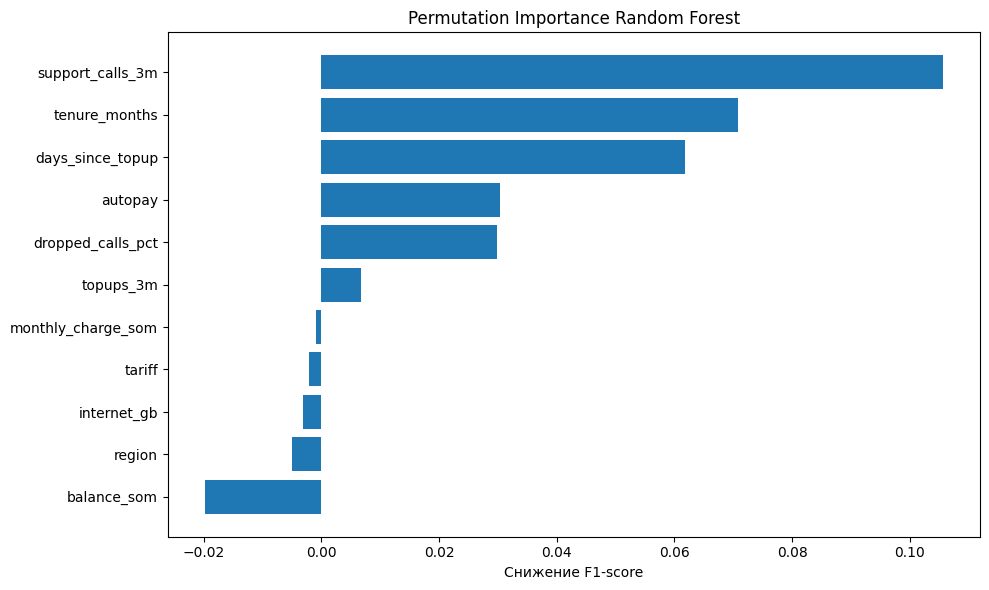

In [11]:
perm_result = permutation_importance(
    random_forest,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Признак": X_test.columns,
    "Permutation Importance": perm_result.importances_mean
}).sort_values("Permutation Importance", ascending=False)

display(permutation_df)

plt.figure(figsize=(10, 6))
plt.barh(
    permutation_df["Признак"],
    permutation_df["Permutation Importance"]
)
plt.gca().invert_yaxis()
plt.title("Permutation Importance Random Forest")
plt.xlabel("Снижение F1-score")
plt.tight_layout()
plt.show()

In [12]:
%pip install shap


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [13]:
import shap

# Берём небольшую выборку для объяснения
X_sample = X_test.sample(
    n=min(100, len(X_test)),
    random_state=42
)

# Преобразуем данные так же, как при обучении модели
X_sample_transformed = random_forest.named_steps[
    "preprocessor"
].transform(X_sample)

explainer = shap.TreeExplainer(
    random_forest.named_steps["model"]
)

shap_values = explainer.shap_values(X_sample_transformed)

print("SHAP успешно рассчитан!")

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP успешно рассчитан!


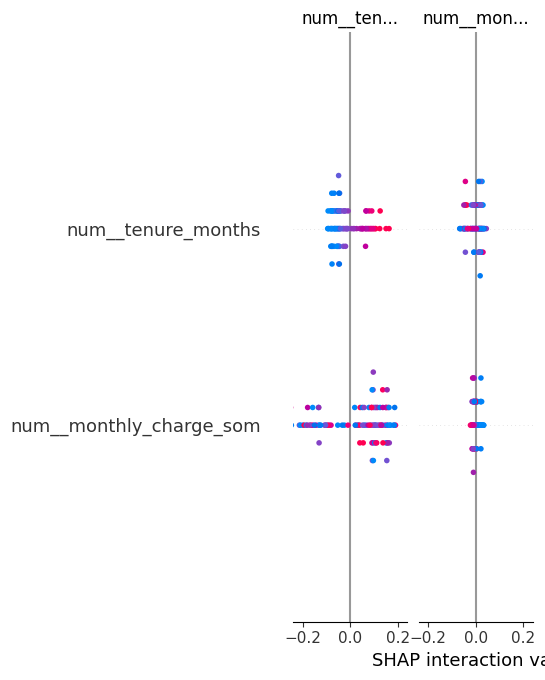

In [14]:
shap.summary_plot(
    shap_values,
    X_sample_transformed,
    feature_names=feature_names,
    show=True
)

In [15]:
# Объясняем предсказания для трёх абонентов
X_individual = X_test.iloc[:3]

X_individual_transformed = random_forest.named_steps[
    "preprocessor"
].transform(X_individual)

explainer = shap.TreeExplainer(
    random_forest.named_steps["model"]
)

shap_individual = explainer(
    X_individual_transformed
)

print("Истинные значения:", y_test.iloc[:3].tolist())
print("Предсказания модели:", random_forest.predict(X_individual).tolist())

Истинные значения: [0, 0, 0]
Предсказания модели: [0, 0, 0]


In [16]:
# Сравниваем первые 10 признаков по двум методам
comparison_df = importance_df.merge(
    permutation_df,
    on="Признак",
    how="outer"
).fillna(0)

display(
    comparison_df.sort_values(
        "Важность",
        ascending=False
    ).head(10)
)

,Признак,Важность,Permutation Importance
25,num__support_calls_3m,0.163660,0.0
26,num__tenure_months,0.160505,0.0
21,num__days_since_topup,0.129955,0.0
22,num__dropped_calls_pct,0.114238,0.0
23,num__internet_gb,0.079135,0.0
24,num__monthly_charge_som,0.069791,0.0
20,num__balance_som,0.069418,0.0
27,num__topups_3m,0.061573,0.0
19,num__autopay,0.058467,0.0
11,cat__tariff_Базовый,0.009384,0.0
